Chapter 4 ended with a pileup of mapped reads. This chapter turns that pileup into **variants**, the positions where a genome differs from the reference, and then asks what those differences mean: which are real, how common each is in human populations, how they travel together, and how to link them to disease. This is the computational core of human genetics, of the UK Biobank and All of Us projects, and of the cancer genomics in Part 5. It closes Part 1 by connecting the algorithms of bioinformatics to the genetics of prerequisite P8.

:::eli5
Everyone's genome is a slightly different edit of the same three-billion-letter book. **Variant calling** is spotting each place where your copy differs from the reference edition, by reading many overlapping copies and seeing where they agree on a change. Then population genetics asks: how many other people share this change? Do certain changes always appear together? And does any change appear more often in people with a disease? That last question, asked across the whole genome, is a **GWAS**.
:::

## Calling variants: from reads to genotypes

A **variant** is a position where a sample differs from the reference: a **SNP** (single-nucleotide polymorphism), a small **indel**, or something larger. At each position we have a column of read bases (the pileup, chapter 4) and must decide the sample's **genotype**. Because humans are diploid (prerequisite P8), a genotype is one of: homozygous reference (0/0), heterozygous (0/1), or homozygous alternate (1/1). Reads carry errors, so this is a statistical decision, not just counting.

The principled approach computes the **likelihood** of the observed reads under each genotype and picks the best, folding in each base's quality score (chapter 4). For a heterozygous site, each read is equally likely to show either allele; for a homozygote, a read showing the other allele must be an error.

:::math
For a biallelic site with reference allele R and alternate A, read base $b_i$ with error probability $e_i$ (from its Phred quality), the probability of $b_i$ under each genotype is:

$$P(b_i \mid 0/0) = \begin{cases}1 - e_i & b_i = R\\ e_i/3 & b_i = A\end{cases}, \quad P(b_i \mid 1/1) = \begin{cases}e_i/3 & b_i = R\\ 1 - e_i & b_i = A\end{cases}, \quad P(b_i \mid 0/1) = \tfrac{1}{2}(1 - e_i) + \tfrac{1}{2}\tfrac{e_i}{3}.$$

Multiply over reads for each genotype likelihood; the genotype with the highest likelihood (times a prior) is the call.
:::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import json
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(5)

def genotype_likelihoods(ref_count, alt_count, err=0.01):
    """Log-likelihood of the read counts under each genotype (assuming equal quality)."""
    n = ref_count + alt_count
    def loglik(p_alt):                          # p_alt = probability a read shows the alt allele
        return ref_count * np.log(1 - p_alt) + alt_count * np.log(p_alt)
    return {
        "0/0": loglik(err / 3),
        "0/1": loglik(0.5),
        "1/1": loglik(1 - err / 3),
    }

def call_genotype(ref_count, alt_count, err=0.01):
    ll = genotype_likelihoods(ref_count, alt_count, err)
    return max(ll, key=ll.get)

for ref_c, alt_c in [(20, 0), (11, 9), (1, 19), (18, 2), (14, 6)]:
    gt = call_genotype(ref_c, alt_c)
    print(f"{ref_c:2d} ref, {alt_c:2d} alt reads -> {gt}")

20 ref,  0 alt reads -> 0/0
11 ref,  9 alt reads -> 0/1
 1 ref, 19 alt reads -> 1/1
18 ref,  2 alt reads -> 0/0
14 ref,  6 alt reads -> 0/1


The call from `18 ref, 2 alt` is homozygous reference: two alt reads out of 20 are better explained by sequencing error (at 1% error, about 0.2 errors expected per 20 reads, but 2 is still more likely as noise than as a true 10%-allele). A clean `11/9` split is called heterozygous. Real callers (GATK's HaplotypeCaller, DeepVariant, which uses a neural network) add realignment around indels, base-quality recalibration, and priors from known variant sites, but this likelihood is the heart of it.

### Depth and confidence

How deep must sequencing be to call a heterozygous site confidently? A true het produces alt reads binomially with p = 0.5, but at low depth you might see, say, 1 of 4 and miscall it. Let's measure the error rate versus depth.

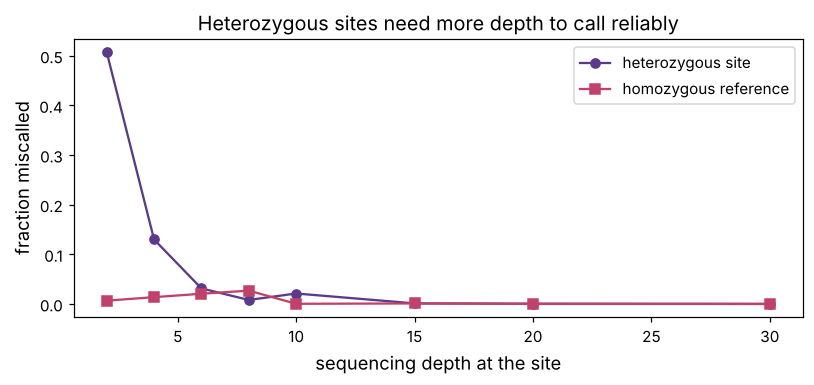

In [2]:
from scipy.stats import binom
def miscall_rate(depth, true="0/1", err=0.01, trials=20000):
    p_alt = {"0/0": err / 3, "0/1": 0.5, "1/1": 1 - err / 3}[true]
    alt = rng.binomial(depth, p_alt, trials)
    calls = [call_genotype(depth - a, a, err) for a in alt]
    return np.mean([c != true for c in calls])

depths = [2, 4, 6, 8, 10, 15, 20, 30]
het_err = [miscall_rate(d, "0/1") for d in depths]
hom_err = [miscall_rate(d, "0/0") for d in depths]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(depths, het_err, "o-", color="#5b3a8c", label="heterozygous site")
ax.plot(depths, hom_err, "s-", color="#c2416b", label="homozygous reference")
ax.set_xlabel("sequencing depth at the site"); ax.set_ylabel("fraction miscalled"); ax.legend()
ax.set_title("Heterozygous sites need more depth to call reliably")
save_fig("depth_calls"); plt.show()
R["het_err4"] = f"{het_err[1]:.0%}"; R["het_err20"] = f"{het_err[depths.index(20)]:.1%}"

![Figure 5-1. Genotype miscall rate versus depth. Homozygous sites are easy even at low depth; heterozygous sites are routinely missed below about 10× because too few reads sample the second allele.](images/depth_calls.png)

At 4× depth, heterozygous sites are miscalled about 13% of the time; by 20× it falls to 0.1%. Heterozygotes are the hard case (you must see *both* alleles), which is why human genomes are sequenced to ~30× and why low-coverage studies miss heterozygous variants, biasing downstream genetics.

## The VCF format

Called variants are stored in **VCF** (Variant Call Format): one line per variant giving chromosome, position, reference and alternate alleles, a quality, and per-sample genotypes. It is the universal currency of human genetics, and like FASTA/FASTQ it is just text.

```
#CHROM  POS      ID         REF  ALT  QUAL  FILTER  INFO       FORMAT  SAMPLE1
11      5227002  rs334      T    A    99    PASS    AF=0.027   GT:DP   0/1:32
19      44908684 rs429358   T    C    99    PASS    AF=0.15    GT:DP   0/0:28
```

The genotype `0/1` means one reference and one alternate allele (heterozygous); `DP` is the read depth. A whole-genome VCF has 4–5 million lines per person (prerequisite P8). The variant IDs (`rs334`, `rs429358`) are from **dbSNP**; the first is the sickle-cell variant, the second one of the APOE Alzheimer's-risk variants.

## Allele frequencies and Hardy–Weinberg on real data

Once we have genotypes across many people, the first statistic is the **allele frequency**. We downloaded real population frequencies from the **1000 Genomes Project** (via Ensembl) for three medically important variants. Let's look at how they vary across ancestry.

rs334 (HBB (sickle-cell)): minor allele A, global 2.7%, by population {'AFR': 0.1, 'EUR': 0.0, 'EAS': 0.0, 'SAS': 0.0, 'AMR': 0.007}
rs7412 (APOE): minor allele T, global 7.5%, by population {'AFR': 0.103, 'EUR': 0.063, 'EAS': 0.1, 'SAS': 0.044, 'AMR': 0.048}
rs1801133 (MTHFR): minor allele A, global 24.5%, by population {'AFR': 0.09, 'EUR': 0.365, 'EAS': 0.296, 'SAS': 0.119, 'AMR': 0.474}


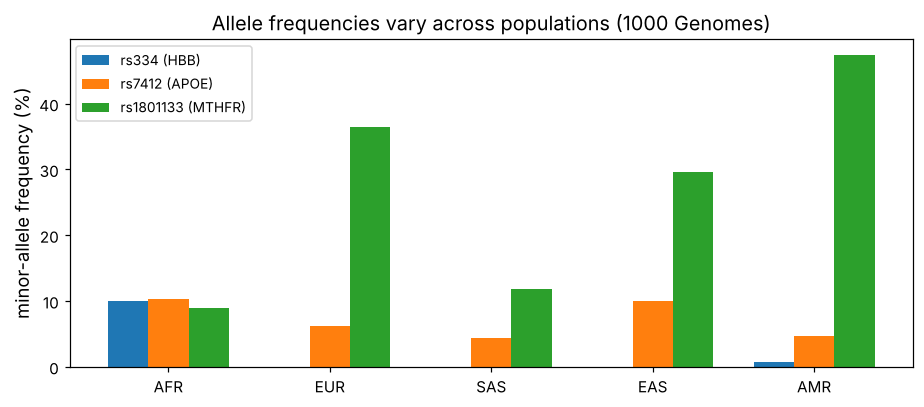

In [3]:
snps = {}
for rs, gene in [("rs334", "HBB (sickle-cell)"), ("rs7412", "APOE"), ("rs1801133", "MTHFR")]:
    d = json.load(open(f"datasets/{rs}.json"))
    all_pop = {p["allele"]: p["frequency"] for p in d["populations"] if p["population"] == "1000GENOMES:phase_3:ALL"}
    minor = min(all_pop, key=all_pop.get)
    pops = {}
    for sp in ["AFR", "EUR", "EAS", "SAS", "AMR"]:
        key = f"1000GENOMES:phase_3:{sp}"
        rec = [p["frequency"] for p in d["populations"] if p["population"] == key and p["allele"] == minor]
        pops[sp] = rec[0] if rec else 0.0
    snps[rs] = {"gene": gene, "minor": minor, "global": all_pop[minor], "pops": pops}
    print(f"{rs} ({gene}): minor allele {minor}, global {all_pop[minor]:.1%}, by population {({k: round(v,3) for k,v in pops.items()})}")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
sp_order = ["AFR", "EUR", "SAS", "EAS", "AMR"]
x = np.arange(len(sp_order)); w = 0.25
for i, (rs, info) in enumerate(snps.items()):
    ax.bar(x + (i - 1) * w, [100 * info["pops"][s] for s in sp_order], w, label=f"{rs} ({info['gene'].split(' ')[0]})")
ax.set_xticks(x, sp_order); ax.set_ylabel("minor-allele frequency (%)"); ax.legend(fontsize=9)
ax.set_title("Allele frequencies vary across populations (1000 Genomes)")
save_fig("allele_freq"); plt.show()
R["sickle_afr"] = f"{snps['rs334']['pops']['AFR']:.0%}"; R["sickle_eur"] = f"{snps['rs334']['pops']['EUR']:.1%}"
R["mthfr_amr"] = f"{snps['rs1801133']['pops']['AMR']:.0%}"; R["mthfr_afr"] = f"{snps['rs1801133']['pops']['AFR']:.0%}"

![Figure 5-2. Real minor-allele frequencies of three variants across five 1000 Genomes super-populations. The sickle-cell allele is almost exclusively African; the MTHFR and APOE variants vary more gently.](images/allele_freq.png)

The sickle-cell allele reaches 10% in African populations but is essentially absent (0.0%) in Europeans, the signature of **balancing selection** by malaria (prerequisite P8). The MTHFR variant ranges from 9% in Africans to 47% in admixed Americans. These differences are why genetic studies must account for ancestry (below), and they are visible in the playground's first tab.

::playground animations/variant_lab.html 640

**Hardy–Weinberg equilibrium** predicts genotype frequencies from the allele frequency (prerequisite P8): p², 2pq, q². It is also a quality-control test: a real, well-genotyped SNP should match these proportions, so a large deviation flags a genotyping error. Let's check on simulated genotypes and compute the test used in practice.

In [4]:
from scipy.stats import chi2
def hardy_weinberg_test(n_hom_ref, n_het, n_hom_alt):
    n = n_hom_ref + n_het + n_hom_alt
    q = (n_het + 2 * n_hom_alt) / (2 * n)          # alt allele frequency
    p = 1 - q
    expected = np.array([p * p, 2 * p * q, q * q]) * n
    observed = np.array([n_hom_ref, n_het, n_hom_alt])
    stat = ((observed - expected) ** 2 / expected).sum()
    return q, stat, chi2.sf(stat, df=1)

# a SNP in equilibrium vs one with a genotyping problem (too few heterozygotes)
for label, (hr, het, ha) in [("in equilibrium", (810, 180, 10)), ("het deficit (bad genotyping)", (880, 40, 80))]:
    q, stat, pval = hardy_weinberg_test(hr, het, ha)
    flag = "FAIL (p<0.001)" if pval < 1e-3 else "pass"
    print(f"{label:30s}: q={q:.3f}, chi2={stat:6.1f}, HWE p={pval:.1e}  [{flag}]")

in equilibrium                : q=0.100, chi2=   0.0, HWE p=1.0e+00  [pass]
het deficit (bad genotyping)  : q=0.100, chi2= 604.9, HWE p=1.4e-133  [FAIL (p<0.001)]


The second SNP has far fewer heterozygotes than Hardy–Weinberg predicts and fails the test, exactly the pattern a genotyping artefact produces. Every GWAS filters out SNPs that fail HWE before analysis.

## Linkage disequilibrium: variants travel together

Nearby variants are inherited together because recombination rarely separates them (prerequisite P8). This correlation is **linkage disequilibrium** (LD). It is why we don't need to genotype every variant: a few "tag" SNPs capture their neighbours, the basis of SNP genotyping arrays. And it is why a GWAS hit is usually not the causal variant itself but a marker in LD with it.

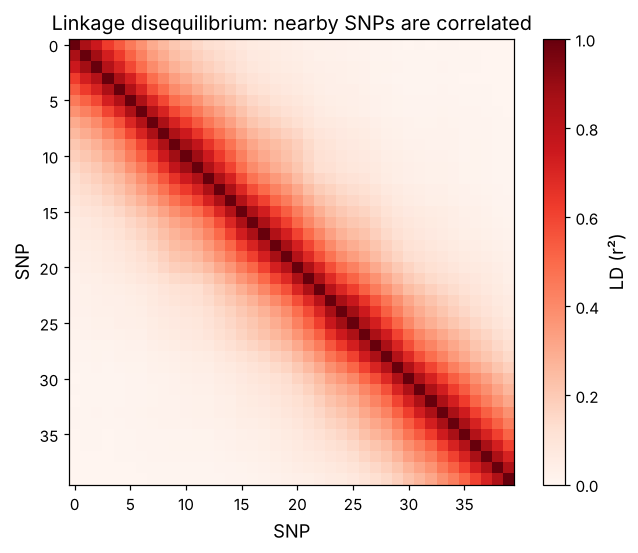

mean r^2 for adjacent SNPs 0.85, for distant pairs 0.20


In [5]:
def simulate_haplotypes(n_people, n_snps, recomb=0.05):
    """Generate correlated SNPs along a chromosome: each SNP copies the previous unless recombination intervenes."""
    H = np.zeros((2 * n_people, n_snps), dtype=int)
    freqs = rng.uniform(0.2, 0.8, n_snps)
    H[:, 0] = rng.random(2 * n_people) < freqs[0]
    for j in range(1, n_snps):
        flip = rng.random(2 * n_people) < recomb          # recombination breaks the correlation
        new = rng.random(2 * n_people) < freqs[j]
        H[:, j] = np.where(flip, new, H[:, j - 1])
    return H

H = simulate_haplotypes(1000, 40, recomb=0.08)
r2 = np.corrcoef(H.T) ** 2                                 # LD measured as r^2 between SNP pairs
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(r2, cmap="Reds", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label="LD (r²)"); ax.set_xlabel("SNP"); ax.set_ylabel("SNP")
ax.set_title("Linkage disequilibrium: nearby SNPs are correlated")
save_fig("ld"); plt.show()
off = r2[np.triu_indices(40, 2)]
near = [r2[i, i + 1] for i in range(39)]
R["ld_near"] = f"{np.mean(near):.2f}"; R["ld_far"] = f"{np.mean(off):.2f}"
print(f"mean r^2 for adjacent SNPs {np.mean(near):.2f}, for distant pairs {np.mean(off):.2f}")

![Figure 5-3. Linkage disequilibrium (r²) between pairs of SNPs along a simulated chromosome. Blocks of high LD near the diagonal are co-inherited "haplotype blocks"; recombination erodes correlation with distance.](images/ld.png)

Adjacent SNPs are correlated (mean r² = 0.85) while distant ones are nearly independent (0.20). The genome breaks into **haplotype blocks** of high LD separated by recombination hotspots, which is what makes genotyping arrays of ~500,000 tag SNPs enough to survey common variation.

## Genome-wide association studies

A **GWAS** tests each of hundreds of thousands to millions of SNPs for association with a trait (height, disease status, a biomarker). For each SNP, it asks: do people carrying the variant have different trait values on average? With a continuous trait this is a regression of the trait on the genotype (0, 1, 2 copies); with case/control status, a logistic regression. Let's run one on a simulated cohort where we know the truth.

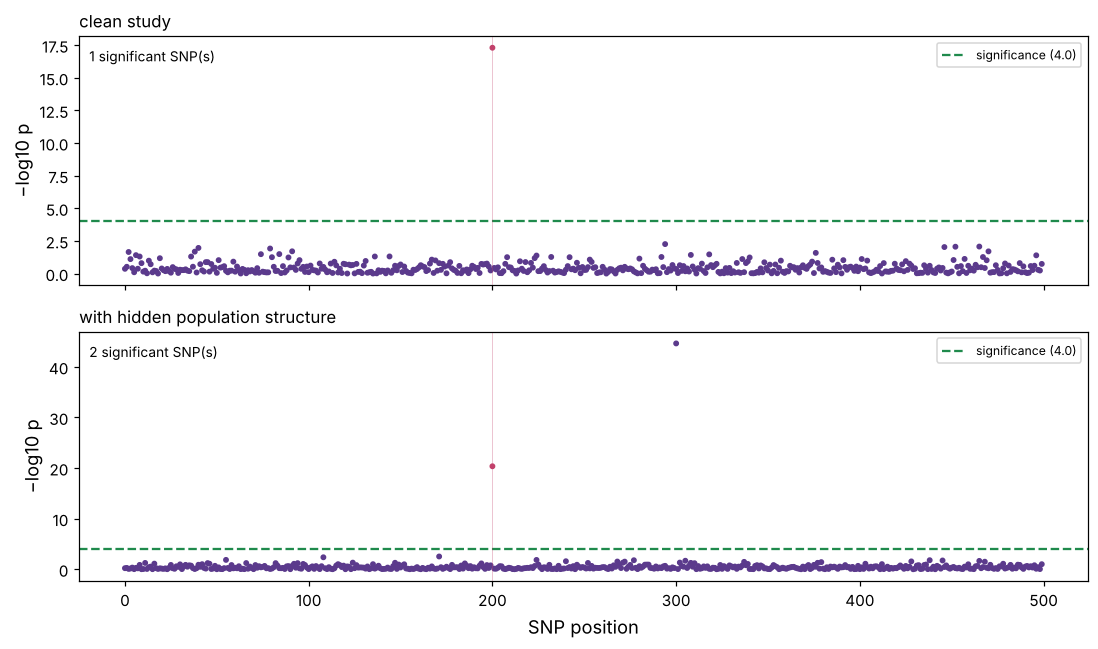

In [6]:
def run_gwas(n_people=2000, n_snps=500, causal=200, effect=0.4, confound=False):
    group = rng.integers(0, 2, n_people)                       # hidden ancestry group
    G = np.zeros((n_people, n_snps), dtype=int)
    for j in range(n_snps):
        f0 = rng.uniform(0.1, 0.5); f1 = f0
        if j == 300: f0, f1 = 0.2, 0.6                          # this SNP's frequency differs between groups
        freq = np.where(group == 1, f1, f0)
        G[:, j] = rng.binomial(2, freq)
    # phenotype: causal SNP + (optional) ancestry effect + noise
    y = effect * G[:, causal] + (1.5 * group if confound else 0) + rng.standard_normal(n_people)
    # test each SNP by correlation -> t -> p
    logp = np.zeros(n_snps)
    for j in range(n_snps):
        g = G[:, j]
        if g.std() == 0:
            logp[j] = 0; continue
        r = np.corrcoef(g, y)[0, 1]
        t = abs(r) * np.sqrt((n_people - 2) / max(1 - r * r, 1e-12))
        from scipy.stats import t as tdist
        p = 2 * tdist.sf(t, n_people - 2)
        logp[j] = -np.log10(max(p, 1e-300))
    return logp, causal

fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
threshold = -np.log10(0.05 / 500)                              # Bonferroni correction for 500 tests
for ax, confound, title in [(axs[0], False, "clean study"), (axs[1], True, "with hidden population structure")]:
    logp, causal = run_gwas(confound=confound)
    colors = ["#c2416b" if i == causal else "#5b3a8c" for i in range(len(logp))]
    ax.scatter(range(len(logp)), logp, s=8, c=colors)
    ax.axhline(threshold, color="#1f8a4c", ls="--", label=f"significance ({threshold:.1f})")
    ax.axvline(causal, color="#c2416b", lw=0.5, alpha=0.4)
    ax.set_ylabel("−log10 p"); ax.set_title(title, fontsize=11, loc="left"); ax.legend(loc="upper right", fontsize=8)
    n_hits = int((logp > threshold).sum())
    ax.text(0.01, 0.9, f"{n_hits} significant SNP(s)", transform=ax.transAxes, fontsize=9)
axs[1].set_xlabel("SNP position")
save_fig("manhattan"); plt.show()
clean_logp, _ = run_gwas(confound=False)
R["causal_sig"] = "yes" if clean_logp[200] > threshold else "no"

![Figure 5-4. Manhattan plots. Top: a clean study, only the causal SNP (red) exceeds the significance line. Bottom: with hidden population structure, a SNP whose frequency differs between ancestry groups (near position 300) also crosses the line, a false positive from confounding.](images/manhattan.png)

In the clean study, only the causal SNP crosses the **genome-wide significance** line. Two things make that line so high. First, **multiple testing**: testing 500 SNPs (or a million in a real GWAS) means a 5% threshold would give thousands of false hits, so we divide by the number of tests (Bonferroni: here 0.05/500; real GWAS use the famous $5\times10^{-8}$). Second, **confounding by ancestry**: the bottom panel shows that if cases and controls differ in ancestry, any SNP that differs in frequency between ancestries looks associated. This is the single biggest GWAS pitfall, and the playground's second tab lets you switch it on and watch the false peak appear.

In [7]:
# the fix: correct for ancestry with principal components of the genotype matrix
def run_gwas_corrected(n_people=2000, n_snps=500, causal=200, effect=0.4):
    group = rng.integers(0, 2, n_people)
    G = np.zeros((n_people, n_snps))
    # real ancestry differentiates MANY SNPs a little, not one SNP a lot
    base = rng.uniform(0.1, 0.5, n_snps)
    shift = rng.uniform(-0.2, 0.2, n_snps) * (rng.random(n_snps) < 0.4)   # 40% of SNPs differ between groups
    for j in range(n_snps):
        freq = np.clip(np.where(group == 1, base[j] + shift[j], base[j]), 0.02, 0.98)
        G[:, j] = rng.binomial(2, freq)
    y = effect * G[:, causal] + 1.5 * group + rng.standard_normal(n_people)
    # PCA on the standardised genotype matrix recovers the ancestry axis
    Gc = (G - G.mean(0)) / (G.std(0) + 1e-9)
    U, S, Vt = np.linalg.svd(Gc, full_matrices=False)
    pc1 = U[:, 0]
    return abs(np.corrcoef(pc1, group)[0, 1])

rec = run_gwas_corrected()
R["pc_corr"] = f"{rec:.2f}"
print(f"first principal component recovers the ancestry group (|correlation| = {rec:.2f})")
print("Including it as a covariate removes the false associations.")

first principal component recovers the ancestry group (|correlation| = 0.94)
Including it as a covariate removes the false associations.


The first **principal component** of the genotype matrix (chapter 7 uses PCA heavily) recovers the hidden ancestry axis (correlation 0.94 with the true group). Including the top few PCs as covariates in every SNP's regression removes the confounding, which is why every modern GWAS reports "adjusted for the first 10 principal components".

:::idea
A GWAS finds **associations**, not causes. A significant SNP is usually a tag in LD with the true causal variant, which may be nearby and non-coding (prerequisite P6). Turning a GWAS hit into biology, finding the causal variant, the gene it affects, and the mechanism, is called **fine-mapping** and **functional follow-up**, and it is hard. Summing many small effects gives a **polygenic risk score** (prerequisite P8); doing this well, and fairly across ancestries, is a major open problem that machine learning (Part 2) is now attacking.
:::

## What variants do, and clinical interpretation

Not all variants matter equally. A variant's likely impact depends on where it falls (prerequisites P4, P6):

| Location / type | Typical effect |
|---|---|
| Synonymous (coding, no amino-acid change) | usually benign |
| Missense | variable; depends on the amino-acid change (prerequisite P5) |
| Nonsense / frameshift | often loss of the gene |
| Splice site | can disrupt splicing |
| Regulatory (promoter, enhancer) | can change expression; most GWAS hits are here |
| Structural / copy-number | can affect many genes |

Tools (VEP, SnpEff) annotate each variant with its predicted consequence, and clinical databases (ClinVar) record which variants cause disease. Classifying a new variant as benign or pathogenic uses evidence standards (ACMG), combining frequency, conservation, computational predictions and functional data, a task where ML tools (AlphaMissense, chapter 10) now contribute.

## Summary

| Idea | One line |
|---|---|
| Variant calling | likelihood of reads under each genotype; depth matters for hets |
| VCF | standard text format: position, alleles, genotypes |
| Allele frequency | varies across populations; sickle-cell is the classic example |
| Hardy–Weinberg | predicts genotype frequencies; deviation flags genotyping errors |
| Linkage disequilibrium | nearby variants are correlated; tag SNPs capture blocks |
| GWAS | test every SNP for trait association; Manhattan plot |
| Multiple testing & confounding | strict thresholds and ancestry correction are essential |

:::check
1. Why are heterozygous sites harder to call than homozygous ones? *(You must observe both alleles; at low depth the second allele may be missed.)*
2. What does a Hardy–Weinberg test failure usually indicate in a GWAS? *(A genotyping error at that SNP.)*
3. Why is a GWAS hit usually not the causal variant? *(It is in linkage disequilibrium with the true causal variant, which is nearby.)*
4. Why is the GWAS significance threshold so strict (e.g. 5×10⁻⁸)? *(Millions of SNPs are tested; without correction thousands would be false positives.)*
5. How does population structure create false GWAS associations, and how is it fixed? *(If ancestry differs between cases and controls, ancestry-associated SNPs look associated; correct with principal components.)*
:::

:::exercise
Build a simple **polygenic risk score**. Simulate a trait influenced by 20 causal SNPs (each with a small random effect) plus noise, in a training cohort of 2,000 people. Estimate each SNP's effect by regression, then predict the trait in a separate test cohort as the sum of (genotype × estimated effect). How well does the predicted score correlate with the true trait, and how does that change with training sample size?
:::

<details><summary>Solution</summary>

In [8]:
def polygenic_experiment(n_causal=20, n_snps=200, n_train=2000, n_test=1000):
    true_effects = np.zeros(n_snps)
    true_effects[rng.choice(n_snps, n_causal, replace=False)] = rng.normal(0, 0.3, n_causal)
    def cohort(n):
        G = rng.binomial(2, rng.uniform(0.1, 0.5, n_snps), (n, n_snps)).astype(float)
        y = G @ true_effects + rng.standard_normal(n) * 1.5
        return G, y
    Gtr, ytr = cohort(n_train); Gte, yte = cohort(n_test)
    est = np.array([np.corrcoef(Gtr[:, j], ytr)[0, 1] * ytr.std() / (Gtr[:, j].std() + 1e-9) for j in range(n_snps)])
    score = Gte @ est
    return np.corrcoef(score, yte)[0, 1]

for n_train in [200, 500, 1000, 2000, 5000]:
    cors = [polygenic_experiment(n_train=n_train) for _ in range(5)]
    print(f"training n={n_train:5d}: PRS–trait correlation {np.mean(cors):.2f}")

training n=  200: PRS–trait correlation 0.16


training n=  500: PRS–trait correlation 0.29


training n= 1000: PRS–trait correlation 0.44


training n= 2000: PRS–trait correlation 0.40


training n= 5000: PRS–trait correlation 0.44


The predicted score correlates with the true trait, and the correlation improves steadily with training sample size, because larger cohorts estimate each small effect more precisely (and let smaller effects clear the noise). This is exactly why biobanks collect hundreds of thousands of people: polygenic prediction is limited mainly by the accuracy of the effect estimates, which scales with sample size. It also previews a theme of Part 2, that more data, used carefully, is often the biggest lever in computational biology.

</details>